In [167]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, precision_recall_curve, auc
from sklearn.ensemble import RandomForestClassifier


Load data and inspect for anomalities

In [168]:

data = pd.read_csv(r"C:\Users\user\OneDrive - Guardian Health Ltd\Desktop\MACHINE LEARNING\CAT1 MODALLING\Risk_Factors.csv")
print(data.head())
print(data.shape)
print(data.info())
print(data.isna().sum())


   Year  Fatal  Serious  Minor           Risk_Factor  Total_Crashes
0  2020   1081     2611   1666  Population Behaviour           5358
1  2019    835     2587   1740  Population Behaviour           5162
2  2018    830     2698   2013  Population Behaviour           5541
3  2017    720     2951   2027  Population Behaviour           5698
4  2016    710     3245   2612  Population Behaviour           6567
(130, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 130 entries, 0 to 129
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Year           130 non-null    int64 
 1   Fatal          130 non-null    int64 
 2   Serious        130 non-null    int64 
 3   Minor          130 non-null    int64 
 4   Risk_Factor    130 non-null    object
 5   Total_Crashes  130 non-null    int64 
dtypes: int64(5), object(1)
memory usage: 6.2+ KB
None
Year             0
Fatal            0
Serious          0
Minor            0
Risk

Converting Numeric columns to numeric

In [169]:
data.columns = ["Year","Fatal","Serious","Minor","Risk_Factor","Total_RTAs"]
numeric_colums =["Year","Fatal","Serious","Minor","Total_RTAs"]
for col in numeric_colums:
    data[col] = pd.to_numeric(data[col], errors ="coerce")

data


,Year,Fatal,Serious,Minor,Risk_Factor,Total_RTAs
0,2020,1081,2611,1666,Population Behaviour,5358
1,2019,835,2587,1740,Population Behaviour,5162
2,2018,830,2698,2013,Population Behaviour,5541
3,2017,720,2951,2027,Population Behaviour,5698
4,2016,710,3245,2612,Population Behaviour,6567
...,...,...,...,...,...,...
125,2015,625,960,1396,Road environment,2981
126,2014,703,990,1292,Road environment,2985
127,2013,585,1008,1302,Road environment,2895
128,2012,621,1108,1242,Road environment,2971


Ploting the graph

<Axes: xlabel='Year', ylabel='Total_RTAs'>

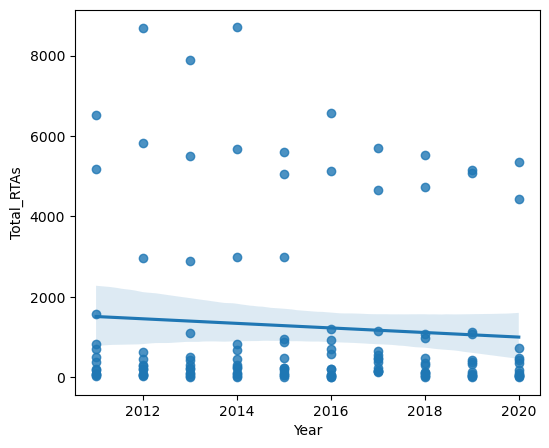

In [170]:
plt.figure(figsize=(6,5))
sns.regplot(data = data, x =data["Year"], y= data["Total_RTAs"])

Linear regression model and evaluating the performance of the model

In [171]:
x =data[["Year"]]
y = data[["Total_RTAs"]]
x_train,x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)


train the model


In [172]:
Model = LinearRegression()
Model.fit(x_train, y_train)
print("intercept", Model.intercept_)
print("coefficient/slope", Model.coef_[0])

intercept [94489.46039314]
coefficient/slope [-46.27605596]


Predict Y values using x_ytest

In [173]:
y_predict_test= Model.predict(x_test)
y_predict_train = Model.predict(x_train)

Visualise the model

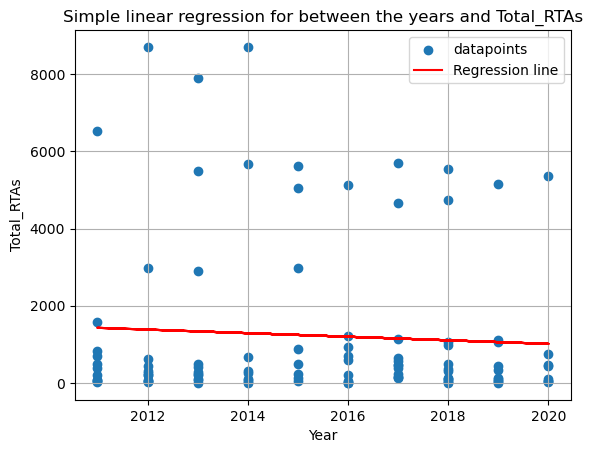

In [174]:
plt.Figure(figsize=(20,10))
plt.scatter(x_train, y_train, label = "datapoints")
plt.plot(x_test, y_predict_test, label = "Regression line", c ="r")
plt.title("Simple linear regression for between the years and Total_RTAs")
plt.xlabel("Year")
plt.ylabel("Total_RTAs")
plt.legend()
plt.grid()
plt.show()

Evaluating model perfoamce using R2_score, Mean Absolute Error

In [175]:
r2train = r2_score(y_train,y_predict_train )
r2test = r2_score(y_test,y_predict_test )
MAE = mean_absolute_error(y_test,y_predict_test)
print("r2train:", r2train)
print("r2test:", r2test)
print("MAE:", MAE)


r2train: 0.0040283521249890875
r2test: 0.007950388604823444
MAE: 1575.2562257139182


b)
Given that risk factor is our target feature, use a decision tree classifier to model the dataset by producing: (6 marks)

i.The Decision Tree diagram

ii.The confusion matrix table.

iii.Precision, recall, and F1-score values.

Separate input features fro target

In [176]:
print(data["Risk_Factor"].value_counts())
x = data.drop(columns = ["Risk_Factor"])
y = data["Risk_Factor"]


Risk_Factor
Population Behaviour       80
Road environment           30
Motor vehicle condition    20
Name: count, dtype: int64


Split data to training and testing

In [177]:
x_train,x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)


Hyperparameter tunning

In [178]:
grid_par ={ "max_depth": range(1,10,1),"min_samples_split":range(2,20,2),"min_samples_leaf": range(1,20,2), "criterion":["entropy","gini"]}
tree = DecisionTreeClassifier(random_state=1)
gridsearch= GridSearchCV(estimator=tree, param_grid=grid_par, cv=5, verbose=True)
gridsearch.fit(x_train,y_train)
Best_score= gridsearch.best_score_
best_estimator = gridsearch.best_estimator_

print("best score:", Best_score)
print(best_estimator)

Fitting 5 folds for each of 1620 candidates, totalling 8100 fits
best score: 0.7019047619047619
DecisionTreeClassifier(criterion='entropy', max_depth=6, min_samples_leaf=3,
                       min_samples_split=10, random_state=1)


Buld and train the decisionTree  classifier

In [179]:
Model= DecisionTreeClassifier(criterion='entropy', max_depth=6, min_samples_leaf=3,
                       min_samples_split=10, random_state=1)
Model.fit(x_train,y_train)


,criterion,'entropy'
,splitter,'best'
,max_depth,6
,min_samples_split,10
,min_samples_leaf,3
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,1
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


Pridicting the risk factor

In [180]:
y_predict = Model.predict(x_test)
Accuracy = accuracy_score(y_test,y_predict)
print("Accuracy:", Accuracy)

Accuracy: 0.8461538461538461


Decision tree diagram

In [181]:
fearure_names = x.columns
class_names = ["Population Behaviour","Road environment", "Motor vehicle condition" ]

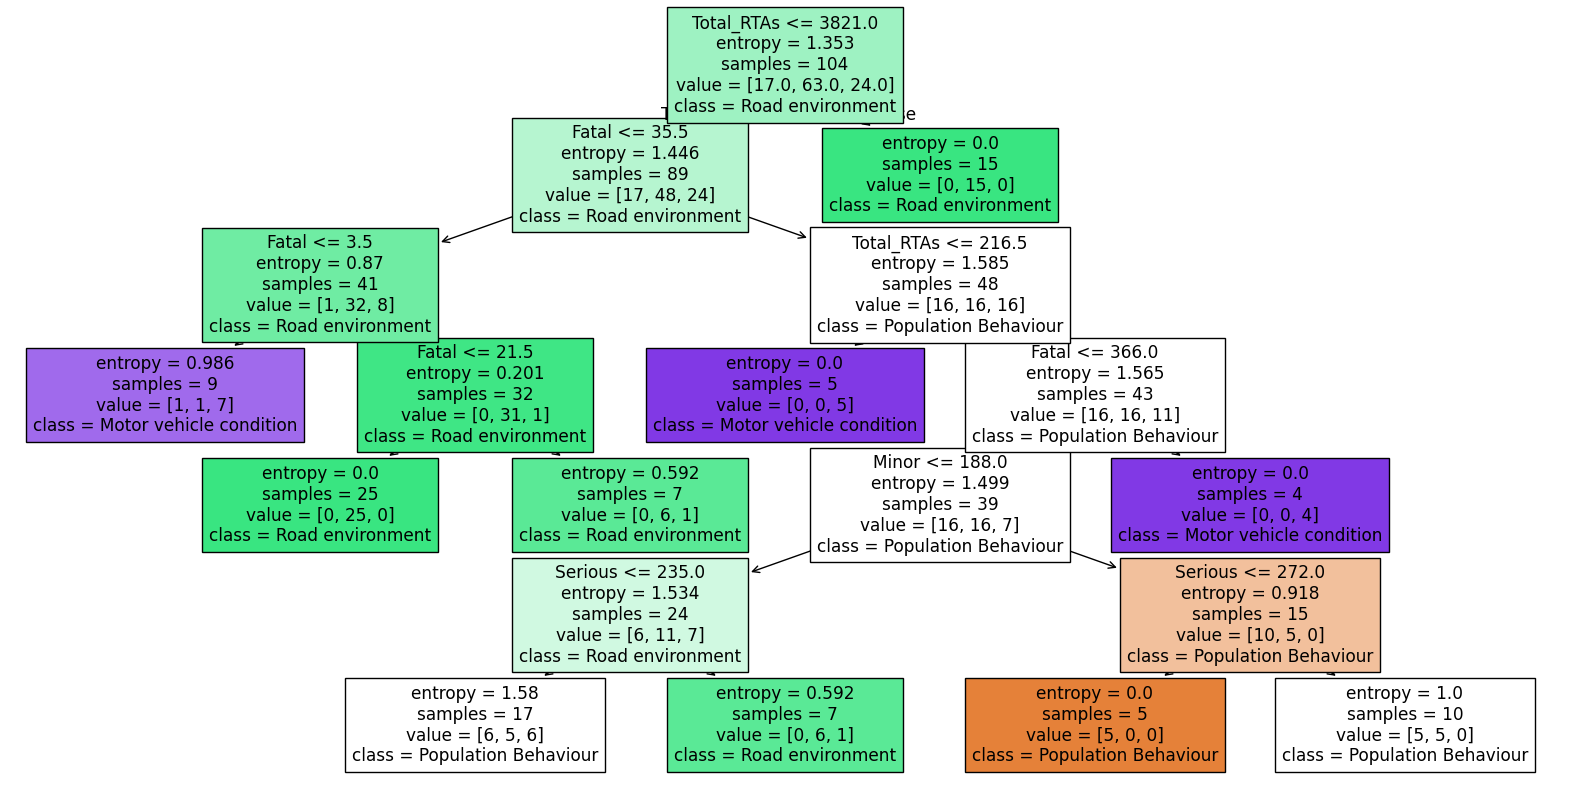

In [182]:
plt.figure(figsize=(20,10))
plot_tree(Model, feature_names =fearure_names, class_names= class_names, filled=True )
plt.show()

Confusion Matrix

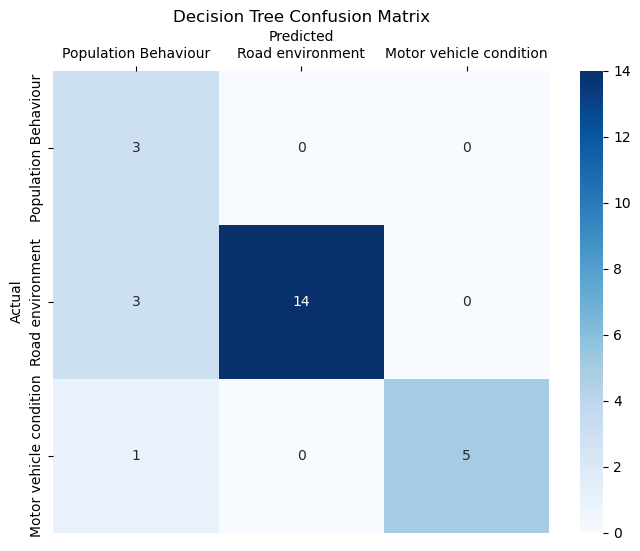

In [183]:
cm = confusion_matrix(y_test,y_predict)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.title("Decision Tree Confusion Matrix")
plt.gca().xaxis.set_label_position("top")
plt.gca().xaxis.set_ticks_position("top")
plt.show()

iii.Precision, recall, and F1-score values.

In [184]:
print(classification_report(y_test,y_predict, target_names=class_names))

                         precision    recall  f1-score   support

   Population Behaviour       0.43      1.00      0.60         3
       Road environment       1.00      0.82      0.90        17
Motor vehicle condition       1.00      0.83      0.91         6

               accuracy                           0.85        26
              macro avg       0.81      0.89      0.80        26
           weighted avg       0.93      0.85      0.87        26



c) Given risk factor is our target feature, use a Random Forest classifier to model the dataset by producing:

i.The confusion matrix table.

ii.Precision, recall, and F1-score values.

d) Produce a graph to show PR-AUC for the population behaviour risk factor. (2 marks)

In [185]:
Model =RandomForestClassifier(n_estimators = 100, random_state=42)
Model.fit(x_train, y_train)
y_predict = Model.predict(x_test)



i.The confusion matrix table.

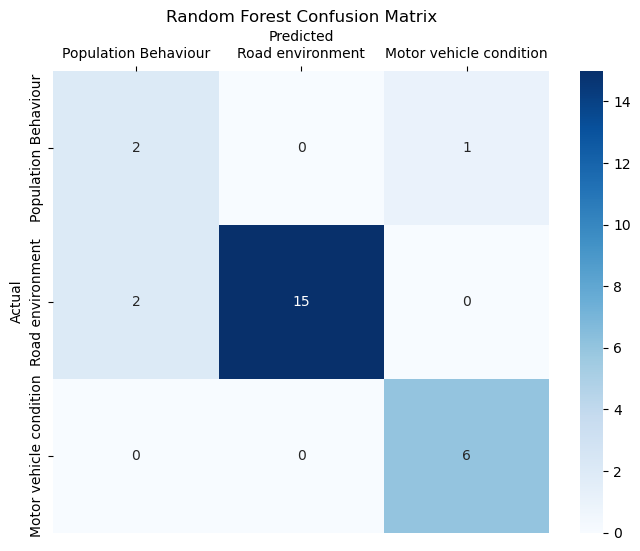

In [186]:
Cm = confusion_matrix(y_test, y_predict)
plt.figure(figsize=(8,6))
sns.heatmap(Cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.title("Random Forest Confusion Matrix")
plt.gca().xaxis.set_label_position("top")
plt.gca().xaxis.set_ticks_position("top")
plt.show()

ii.Precision, recall, and F1-score values.

In [187]:
print("Random Forest Classification Report:")
print(classification_report(y_test,y_predict, target_names=class_names))

Random Forest Classification Report:
                         precision    recall  f1-score   support

   Population Behaviour       0.50      0.67      0.57         3
       Road environment       1.00      0.88      0.94        17
Motor vehicle condition       0.86      1.00      0.92         6

               accuracy                           0.88        26
              macro avg       0.79      0.85      0.81        26
           weighted avg       0.91      0.88      0.89        26



d) Produce a graph to show PR-AUC for the population behaviour risk factor. (2 marks)

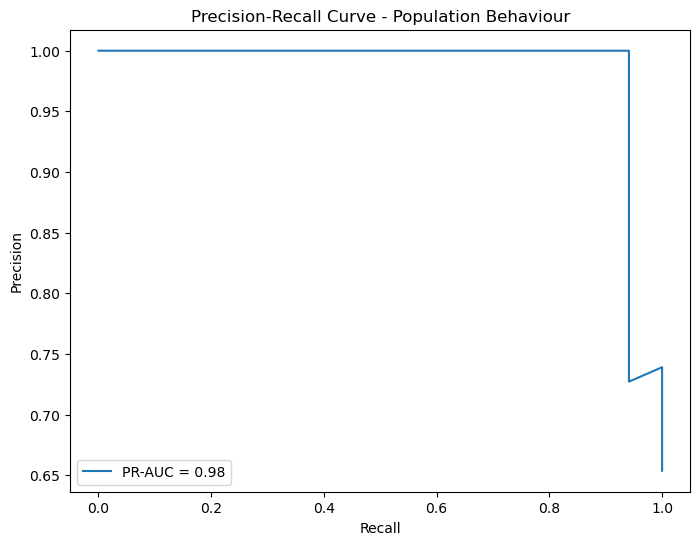

In [192]:
#Graph showing PR-AUC for Population Behaviour
target_class = "Population Behaviour"
y_test_binary = (y_test == target_class).astype(int)
class_index = list(Model.classes_).index(target_class)
y_score = Model.predict_proba(x_test)[:, class_index]
precision, recall, thresholds = precision_recall_curve(y_test_binary, y_score)
pr_auc = auc(recall, precision)
plt.figure(figsize=(8,6))
plt.plot(recall, precision, label=f'PR-AUC = {pr_auc:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall Curve - {target_class}')
plt.legend(loc='best')
plt.show()
